### **AdaBoost (Adaptive Boosting) is a machine learning ensemble meta-algorithm that sequentially combines multiple low-performance weak learners into a single high-performance strong classifier**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [2]:
data = load_breast_cancer(as_frame=True)

df = data.frame

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:", df.isnull().sum().sum())

print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())

df.info()

Dataset shape: (569, 31)

Columns:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

Missing values: 0

Target distribution:
target
0    212
1    357
Name: count, dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             5

In [4]:
X = df.drop("target", axis=1)
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


#### **AdaBoost stands for Adaptive Boosting - Ensemble Learning**

1. Trains the first weak learner.
2. Identifies the samples that were classified incorrectly.
3. Increases the importance of those samples for the next learner.
4. Trains another learner that pays more attention to the difficult samples.
5. Repeats this process for additional learners.
6. Combines the learners' predictions using weighted voting.

| Feature               | Random Forest                        | AdaBoost                                    |
| --------------------- | ------------------------------------ | ------------------------------------------- |
| Ensemble method       | Bagging                              | Boosting                                    |
| How trees are trained | Usually independently                | Sequentially                                |
| Focus on mistakes     | No automatic sequential correction   | Later learners emphasize difficult samples  |
| Combining predictions | Usually majority voting or averaging | Weighted combination of learner predictions |
| Typical base learners | Deeper decision trees                | Often shallow decision trees                |


In [ ]:
base_tree = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

ada_model = AdaBoostClassifier(

    estimator=base_tree, # Specifices the type of weak learner

    n_estimators=100, # Controls the no.of weak learners 
    learning_rate=1.0,
    random_state=42
)

print(ada_model)

ada_model.fit(X_train, y_train)

print("AdaBoost model trained successfully!")

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1,
                                                    random_state=42),
                   n_estimators=100, random_state=42)
AdaBoost model trained successfully!


In [9]:
y_pred_ada = ada_model.predict(X_test)

print("Actual values:", y_test.head(10).tolist())
print("Predicted values:", y_pred_ada[:10].tolist())

Actual values: [0, 1, 0, 1, 0, 1, 1, 0, 0, 0]
Predicted values: [0, 1, 0, 0, 0, 1, 1, 0, 0, 0]


In [10]:
print("Accuracy:", accuracy_score(y_test, y_pred_ada))

print("Precision:", precision_score(y_test, y_pred_ada))

print("Recall:", recall_score(y_test, y_pred_ada))

print("F1 Score:", f1_score(y_test, y_pred_ada))

Accuracy: 0.956140350877193
Precision: 0.9466666666666667
Recall: 0.9861111111111112
F1 Score: 0.9659863945578231


In [11]:
print(
    classification_report(
        y_test,
        y_pred_ada,
        target_names=data.target_names
    )
)

              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



[[38  4]
 [ 1 71]]


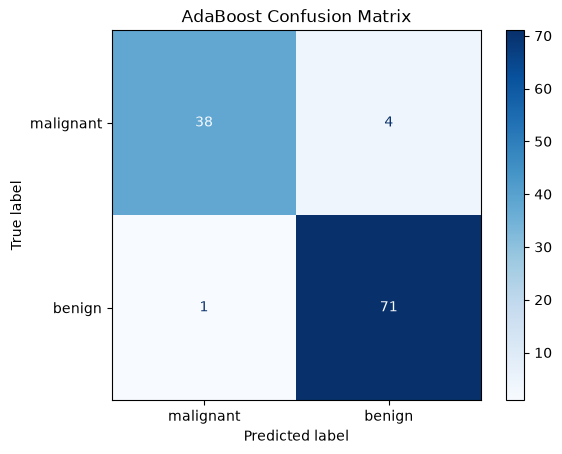

In [12]:
cm = confusion_matrix(y_test, y_pred_ada)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot(cmap="Blues")
plt.title("AdaBoost Confusion Matrix")
plt.show()

In [13]:
print("Number of trained learners:", len(ada_model.estimators_))

Number of trained learners: 100


In [14]:
first_tree = ada_model.estimators_[0]

print("Tree depth:", first_tree.get_depth())
print("Number of leaves:", first_tree.get_n_leaves())

Tree depth: 1
Number of leaves: 2


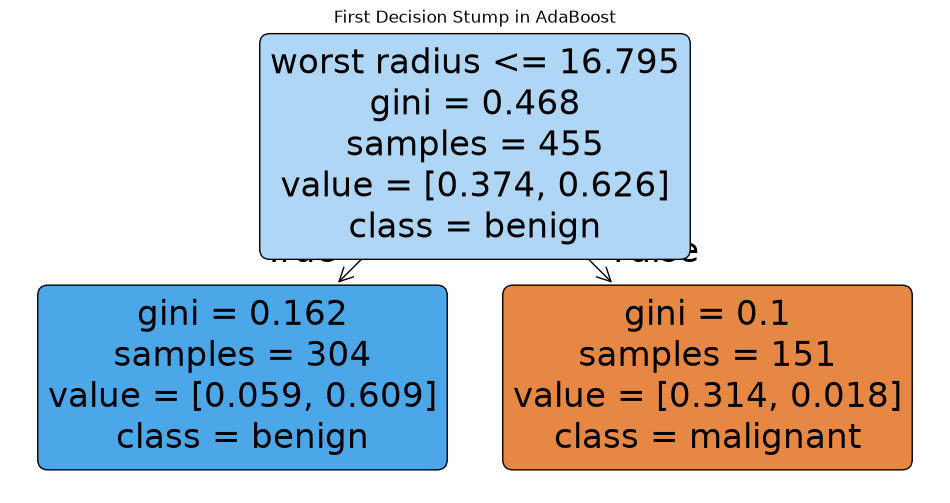

In [15]:
plt.figure(figsize=(12, 6))

from sklearn.tree import plot_tree

plot_tree(
    first_tree,
    feature_names=X.columns,
    class_names=data.target_names,
    filled=True,
    rounded=True
)

plt.title("First Decision Stump in AdaBoost")
plt.show()

#### This returns the model's estimated probabilities for the malignant and benign classes.

#### For each sample, the predicted class generally corresponds to the class with the highest estimated probability.

In [16]:
y_prob_ada = ada_model.predict_proba(X_test)

probability_df = pd.DataFrame(
    y_prob_ada,
    columns=data.target_names,
    index=y_test.index
)

probability_df.head(10)

,malignant,benign
256,0.771519,0.228481
428,0.235618,0.764382
501,0.656795,0.343205
363,0.507591,0.492409
564,0.776289,0.223711
464,0.365776,0.634224
358,0.161284,0.838716
343,0.789495,0.210505
516,0.733254,0.266746
567,0.799815,0.200185
